# Hand Gesture Classification

Three classes: **thumbs_up**, **thumbs_down**, **stop**. Compare a simple CNN, a regularized CNN, and MobileNetV2.

All three models were trained on hand crops. This corrects the mismatch between personal hand close-ups and internet full-body scenes. Training sources receive equal total weight so augmented personal photos do not dominate the objective.

The original external split remains fixed: 135 train, 45 validation, 45 test, with distinct participants. Personal originals and their variants are training only. Model settings and checkpoints are chosen using validation. The previously inspected test split is reused for comparison; it is not a new independent benchmark.

**Default: load saved models.** Set `RUN_TRAINING = True` only to retrain. Three model files and one training-history file live in `models`. No additional image folders are created.


In [1]:
%pip install tensorflow scikit-learn matplotlib numpy pandas pillow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports and settings

Run cells in order. Inputs are 128 × 128 RGB crops; labels 0, 1, 2 correspond to the class order below.


In [3]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "dataset").is_dir():
    ROOT = ROOT.parent
classes = ["thumbs_up", "thumbs_down", "stop"]
IMG_SIZE = 128
SEED = 42
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
assert (ROOT / "dataset").is_dir(), "Open the notebook inside the project folder"

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)

RUN_TRAINING = True
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)
HISTORY_PATH = MODELS_DIR / "training_history.json"
saved_runs = json.loads(HISTORY_PATH.read_text()) if HISTORY_PATH.exists() else {"histories": {}}
histories = saved_runs["histories"]
models = {}
NOTEBOOK_NAME = "02_gesture_project.ipynb"
# Box coordinates are stored inside this notebook, so no extra annotation folder is needed.
notebook_path = ROOT / "notebooks" / NOTEBOOK_NAME
crop_metadata = json.loads(notebook_path.read_text(encoding="utf-8-sig"))["metadata"]["gesture_project"]
hand_boxes = crop_metadata["hand_boxes"]
CROP_MARGIN = crop_metadata["crop_margin"]

print("Training enabled:", RUN_TRAINING)
print("TensorFlow:", tf.__version__)


Training enabled: True
TensorFlow: 2.21.0


## 2. Load the annotated hand crops

Crop coordinates are verified dataset annotations stored inside the notebook. The models classify an already located hand. This is not an automatic full-image hand detector. Originals are only read.


In [4]:
def crop_hand(image, box):
    x, y, width, height = box
    image_width, image_height = image.size
    x, y = x * image_width, y * image_height
    width, height = width * image_width, height * image_height
    side = max(width, height) * (1 + 2 * CROP_MARGIN)
    center_x, center_y = x + width / 2, y + height / 2
    return image.crop((int(center_x - side / 2), int(center_y - side / 2),
                       int(center_x + side / 2), int(center_y + side / 2)))

def read_hand(path):
    relative_path = path.relative_to(ROOT).as_posix()
    assert relative_path in hand_boxes, f"Add a hand box for the new image: {relative_path}"
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        cropped = crop_hand(image, hand_boxes[relative_path])
        return ImageOps.pad(cropped, (IMG_SIZE, IMG_SIZE))

def load_images(folder):
    images, labels, paths = [], [], []
    for label_id, label in enumerate(classes):
        for path in sorted((ROOT / folder / label).iterdir()):
            if not path.is_file() or path.suffix.lower() not in VALID_EXT:
                continue
            relative_path = path.relative_to(ROOT).as_posix()
            assert hashlib.sha256(path.read_bytes()).hexdigest() == crop_metadata["image_sha256"][relative_path], f"Image changed: {relative_path}"
            images.append(np.asarray(read_hand(path), dtype=np.float32) / 255.0)
            labels.append(label_id)
            paths.append(path)
    return np.stack(images), np.array(labels, dtype=np.int32), paths

X_original, y_original, original_files = load_images("dataset")
X_augmented, y_augmented, augmented_files = load_images("augmented")
X_external, y_external, external_files = load_images("external")
print("Original:", X_original.shape, "Augmented:", X_augmented.shape, "External:", X_external.shape)


Original: (28, 128, 128, 3) Augmented: (197, 128, 128, 3) External: (225, 128, 128, 3)


## 3. Fixed split and source weights

Only external images are stratified 60/20/20. All personal images and variants belong to training. The original split and seed are preserved. Equal total weight for personal and internet sources affects training loss; evaluation metrics are unweighted.


In [5]:
ext_train_idx, remaining = train_test_split(np.arange(len(X_external)), test_size=0.4,
    stratify=y_external, random_state=SEED)
val_idx, test_idx = train_test_split(remaining, test_size=0.5,
    stratify=y_external[remaining], random_state=SEED)
X_train = np.concatenate([X_original, X_augmented, X_external[ext_train_idx]])
y_train = np.concatenate([y_original, y_augmented, y_external[ext_train_idx]])
sources = np.concatenate([np.zeros(len(X_original) + len(X_augmented), dtype=int),
                          np.ones(len(ext_train_idx), dtype=int)])
order = np.random.default_rng(SEED).permutation(len(X_train))
X_train, y_train, sources = X_train[order], y_train[order], sources[order]
sample_weight = np.where(sources == 0, len(sources) / (2 * (sources == 0).sum()),
                         len(sources) / (2 * (sources == 1).sum())).astype("float32")
X_val, y_val = X_external[val_idx], y_external[val_idx]
display(pd.DataFrame({"train": np.bincount(y_train), "validation": np.bincount(y_val),
                      "test": np.bincount(y_external[test_idx])}, index=classes))
assert not (set(ext_train_idx) & set(val_idx) or set(ext_train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
assert len(set(crop_metadata["image_sha256"].values())) == 450
print("Source weights:", float(sample_weight[sources == 0][0]), float(sample_weight[sources == 1][0]))


,train,validation,test
thumbs_up,120,15,15
thumbs_down,120,15,15
stop,120,15,15


Source weights: 0.800000011920929 1.3333333730697632


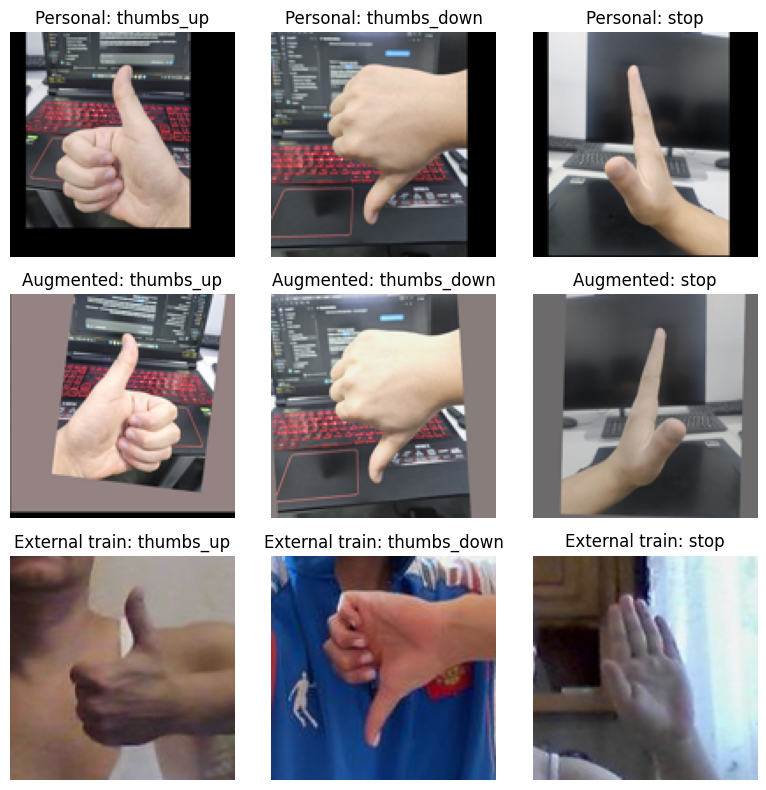

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for row, (name, images, labels) in enumerate([
    ("Personal", X_original, y_original), ("Augmented", X_augmented, y_augmented),
    ("External train", X_external[ext_train_idx], y_external[ext_train_idx])]):
    for col, label in enumerate(classes):
        axes[row, col].imshow(images[np.flatnonzero(labels == col)[0]])
        axes[row, col].set_title(f"{name}: {label}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()


## 4. Train or load

EarlyStopping selects the checkpoint with the highest validation accuracy. A plateau does not overwrite the earlier best checkpoint. ReduceLROnPlateau monitors validation loss to adjust the learning rate. Training histories are saved alongside model files.

The saved curves describe actual training runs. They are loaded when training is disabled. The initial runs used TensorFlow 2.21 and seed 42. Numerical results can vary between computers and runtimes; the initial baseline also disabled oneDNN optimizations. Historical candidate records in the history file describe the initial search only.


In [7]:
def train_or_load(name, filename, builder, epochs, batch_size, patience, min_lr=1e-5):
    path = MODELS_DIR / filename
    if RUN_TRAINING:
        keras.utils.set_random_seed(SEED)
        model = builder()
        history = model.fit(X_train, y_train, sample_weight=sample_weight,
            validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                patience=patience, restore_best_weights=True, verbose=1),
                keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                patience=4, min_lr=min_lr)], verbose=2)
        histories[name] = history.history
        model.save(path)
        saved_runs["histories"] = histories
        predicted = model.predict(X_val, verbose=0).argmax(axis=1)
        saved_runs.setdefault("validation_accuracy", {})[name] = float(accuracy_score(y_val, predicted))
        saved_runs.setdefault("current_runs", {})[name] = {
            "epochs": len(history.history["loss"]),
            "best_epoch": int(np.argmax(history.history["val_accuracy"])) + 1,
            "parameters": model.count_params(), "seed": SEED}
        HISTORY_PATH.write_text(json.dumps(saved_runs, indent=1))
    else:
        model = keras.models.load_model(path)
        print("Loaded:", filename)
    models[name] = model
    history = histories[name]
    print("Best recorded validation accuracy:", round(max(history["val_accuracy"]), 4))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(np.arange(1, len(history[metric]) + 1), history[metric], label="train")
        ax.plot(np.arange(1, len(history[metric]) + 1), history["val_" + metric], label="validation")
        ax.set(title=f"{name}: {metric}", xlabel="Epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()
    return model


## 5. Baseline CNN

Three convolution blocks preserve hand shape. A small spatial pooling layer reduces the large Dense layer used in the original baseline. This model learns from scratch.


Epoch 1/70
23/23 - 4s - 186ms/step - accuracy: 0.4111 - loss: 1.0941 - val_accuracy: 0.3556 - val_loss: 1.0782 - learning_rate: 5.0000e-04
Epoch 2/70
23/23 - 1s - 64ms/step - accuracy: 0.5778 - loss: 1.0051 - val_accuracy: 0.6000 - val_loss: 0.9374 - learning_rate: 5.0000e-04
Epoch 3/70
23/23 - 1s - 63ms/step - accuracy: 0.7972 - loss: 0.7165 - val_accuracy: 0.6667 - val_loss: 0.7506 - learning_rate: 5.0000e-04
Epoch 4/70
23/23 - 1s - 61ms/step - accuracy: 0.8222 - loss: 0.4962 - val_accuracy: 0.7111 - val_loss: 0.6829 - learning_rate: 5.0000e-04
Epoch 5/70
23/23 - 1s - 61ms/step - accuracy: 0.8861 - loss: 0.3707 - val_accuracy: 0.7111 - val_loss: 0.6107 - learning_rate: 5.0000e-04
Epoch 6/70
23/23 - 1s - 61ms/step - accuracy: 0.9167 - loss: 0.3179 - val_accuracy: 0.7111 - val_loss: 0.4813 - learning_rate: 5.0000e-04
Epoch 7/70
23/23 - 1s - 63ms/step - accuracy: 0.9167 - loss: 0.2742 - val_accuracy: 0.7111 - val_loss: 0.6472 - learning_rate: 5.0000e-04
Epoch 8/70
23/23 - 1s - 64ms/step

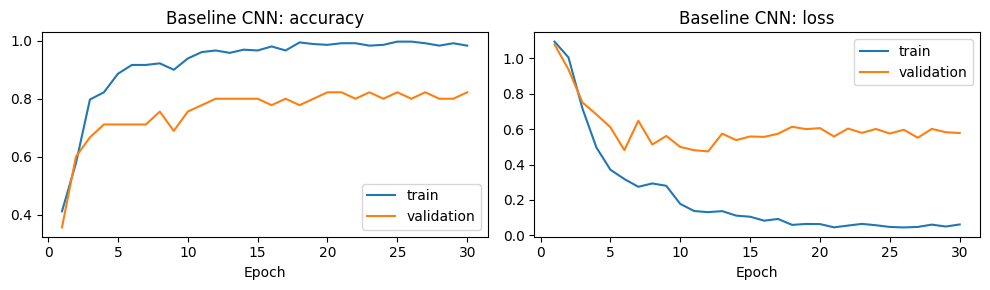

In [8]:
def build_baseline(config):
    model=keras.Sequential(name='baseline_cnn')
    model.add(layers.Input((128,128,3)))
    if config['augmentation']:
        model.add(layers.RandomFlip('horizontal',seed=42))
        model.add(layers.RandomRotation(0.015,fill_mode='reflect',seed=43))
        model.add(layers.RandomTranslation(0.04,0.04,fill_mode='reflect',seed=44))
    for filters in config['filters']:
        model.add(layers.Conv2D(filters,3,padding='same',activation='relu'))
        model.add(layers.MaxPooling2D())
    model.add(layers.AveragePooling2D(config['final_pool']))
    model.add(layers.Flatten())
    model.add(layers.Dense(64,activation='relu'))
    model.add(layers.Dense(3,activation='softmax'))
    model.compile(optimizer=keras.optimizers.Adam(config['learning_rate']),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model

baseline_config = {'name': 'baseline_c', 'filters': [24, 48, 96], 'final_pool': 2, 'augmentation': True, 'learning_rate': 0.0005}
baseline_model = train_or_load("Baseline CNN", "baseline_cnn.keras",
    lambda: build_baseline(baseline_config), epochs=70, batch_size=16, patience=10, min_lr=1e-6)


## 6. Improved CNN

Four compact convolution blocks use BatchNormalization, mild online augmentation, and a small regularized head. Spatial structure is retained to distinguish thumb direction. This model also learns from scratch.


Epoch 1/60
12/12 - 8s - 677ms/step - accuracy: 0.4694 - loss: 2.9657 - val_accuracy: 0.3333 - val_loss: 1.1735 - learning_rate: 0.0010
Epoch 2/60
12/12 - 3s - 283ms/step - accuracy: 0.6306 - loss: 0.9143 - val_accuracy: 0.3556 - val_loss: 1.2635 - learning_rate: 0.0010
Epoch 3/60
12/12 - 4s - 295ms/step - accuracy: 0.7361 - loss: 0.6716 - val_accuracy: 0.6222 - val_loss: 0.8768 - learning_rate: 0.0010
Epoch 4/60
12/12 - 4s - 325ms/step - accuracy: 0.7833 - loss: 0.5341 - val_accuracy: 0.7111 - val_loss: 0.6558 - learning_rate: 0.0010
Epoch 5/60
12/12 - 4s - 316ms/step - accuracy: 0.8472 - loss: 0.4275 - val_accuracy: 0.8444 - val_loss: 0.4731 - learning_rate: 0.0010
Epoch 6/60
12/12 - 4s - 297ms/step - accuracy: 0.8750 - loss: 0.3790 - val_accuracy: 0.8222 - val_loss: 0.3868 - learning_rate: 0.0010
Epoch 7/60
12/12 - 4s - 294ms/step - accuracy: 0.9028 - loss: 0.2805 - val_accuracy: 0.9333 - val_loss: 0.2969 - learning_rate: 0.0010
Epoch 8/60
12/12 - 4s - 294ms/step - accuracy: 0.9083 -

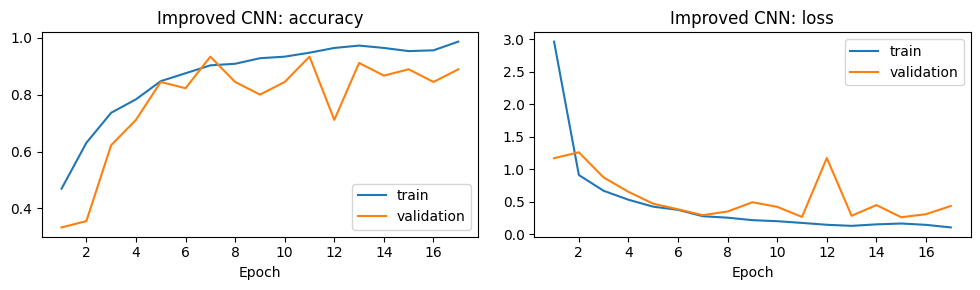

In [9]:
def build_improved_model():
    model = keras.Sequential([
        layers.Input(shape=(128, 128, 3)),
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.025, fill_mode='reflect'),
        layers.RandomZoom(0.08, fill_mode='reflect'),
        layers.RandomTranslation(0.03, 0.03, fill_mode='reflect'),
        layers.RandomContrast(0.10, value_range=(0, 1)),
    ], name='improved_cnn')
    for filters in (24, 48, 96, 128):
        model.add(layers.Conv2D(filters, 3, padding='same', use_bias=False,
                               kernel_regularizer=keras.regularizers.l2(1e-4)))
        model.add(layers.BatchNormalization(momentum=0.9))
        model.add(layers.Activation('relu'))
        model.add(layers.MaxPooling2D())
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)))
    model.add(layers.Dropout(0.35))
    model.add(layers.Dense(3, activation='softmax'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

improved_model = train_or_load("Improved CNN", "improved_cnn.keras",
    build_improved_model, epochs=60, batch_size=32, patience=10)


## 7. MobileNetV2

The ImageNet backbone stays frozen. A small new classifier learns the three gestures. Input [0, 1] is rescaled to [-1, 1] inside the model. Fine-tuning is not needed for the saved run.


Epoch 1/60
12/12 - 10s - 804ms/step - accuracy: 0.3111 - loss: 1.5016 - val_accuracy: 0.3778 - val_loss: 1.1895 - learning_rate: 0.0010
Epoch 2/60
12/12 - 2s - 188ms/step - accuracy: 0.5528 - loss: 0.9826 - val_accuracy: 0.6444 - val_loss: 0.9227 - learning_rate: 0.0010
Epoch 3/60
12/12 - 2s - 184ms/step - accuracy: 0.7361 - loss: 0.7131 - val_accuracy: 0.6889 - val_loss: 0.7456 - learning_rate: 0.0010
Epoch 4/60
12/12 - 2s - 180ms/step - accuracy: 0.7917 - loss: 0.5660 - val_accuracy: 0.8000 - val_loss: 0.6598 - learning_rate: 0.0010
Epoch 5/60
12/12 - 2s - 186ms/step - accuracy: 0.8750 - loss: 0.4143 - val_accuracy: 0.7778 - val_loss: 0.5582 - learning_rate: 0.0010
Epoch 6/60
12/12 - 2s - 190ms/step - accuracy: 0.8861 - loss: 0.3723 - val_accuracy: 0.8000 - val_loss: 0.5044 - learning_rate: 0.0010
Epoch 7/60
12/12 - 2s - 189ms/step - accuracy: 0.9028 - loss: 0.3654 - val_accuracy: 0.8222 - val_loss: 0.4703 - learning_rate: 0.0010
Epoch 8/60
12/12 - 2s - 177ms/step - accuracy: 0.9167 

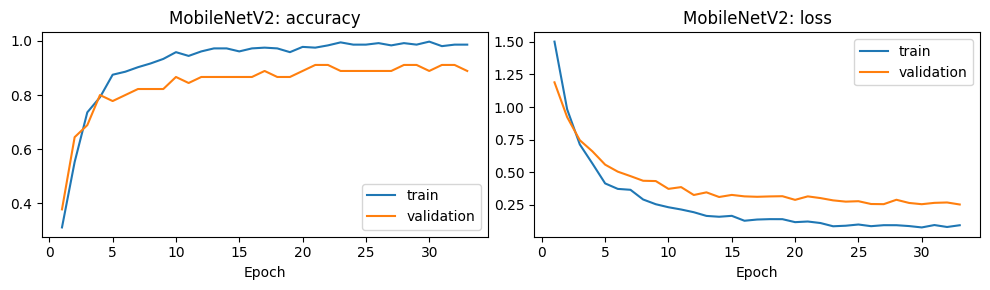

In [10]:
def build_transfer_model():
    base=keras.applications.MobileNetV2(input_shape=(128,128,3),include_top=False,weights='imagenet')
    base.trainable=False
    augmentation=keras.Sequential([
        layers.RandomFlip('horizontal'),layers.RandomRotation(.025),
        layers.RandomZoom(.05),layers.RandomTranslation(.04,.04),
        layers.RandomContrast(.1,value_range=(0.,1.))])
    inputs=keras.Input((128,128,3))
    x=augmentation(inputs)
    x=layers.Rescaling(2.,offset=-1)(x)
    x=base(x,training=False)
    x=layers.GlobalAveragePooling2D()(x)
    x=layers.Dropout(.2)(x)
    outputs=layers.Dense(3,activation='softmax')(x)
    model=keras.Model(inputs,outputs,name='gesture_mobilenet_v2')
    model.compile(optimizer=keras.optimizers.Adam(.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model,base

transfer_model = train_or_load("MobileNetV2", "mobilenet_v2.keras",
    lambda: build_transfer_model()[0], epochs=60, batch_size=32, patience=12)


## 8. Validation comparison

Use validation for model selection. The test split below has not been used to train weights or choose candidate settings in this revision.


In [11]:
validation_scores = {}
for name, model in models.items():
    predicted = model.predict(X_val, verbose=0).argmax(axis=1)
    validation_scores[name] = accuracy_score(y_val, predicted)
display(pd.Series(validation_scores, name="Validation accuracy"))
best_name = max(validation_scores, key=validation_scores.get)
print("Selected using validation:", best_name)


Baseline CNN    0.822222
Improved CNN    0.933333
MobileNetV2     0.911111
Name: Validation accuracy, dtype: float64

Selected using validation: Improved CNN


## 9. Final test results

All models use the same 45 test hand crops. Accuracy is the fraction of correct answers. Macro precision, recall and F1 give all three classes equal weight. Test results describe classification with annotated hand locations, not full-frame hand detection.


Baseline CNN
              precision    recall  f1-score   support

   thumbs_up       0.83      1.00      0.91        15
 thumbs_down       0.93      0.87      0.90        15
        stop       0.85      0.73      0.79        15

    accuracy                           0.87        45
   macro avg       0.87      0.87      0.86        45
weighted avg       0.87      0.87      0.86        45

Improved CNN
              precision    recall  f1-score   support

   thumbs_up       0.93      0.87      0.90        15
 thumbs_down       0.93      0.93      0.93        15
        stop       0.81      0.87      0.84        15

    accuracy                           0.89        45
   macro avg       0.89      0.89      0.89        45
weighted avg       0.89      0.89      0.89        45

MobileNetV2
              precision    recall  f1-score   support

   thumbs_up       0.81      0.87      0.84        15
 thumbs_down       0.93      0.87      0.90        15
        stop       0.87      0.87    

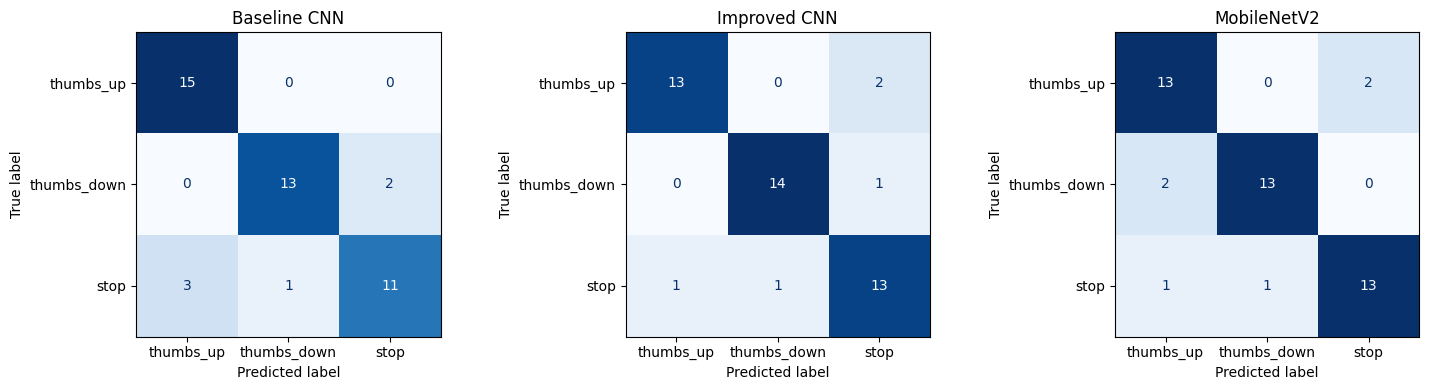

,Correct,Total,Accuracy,Precision,Recall,F1
Model,,,,,,
Baseline CNN,39,45,0.867,0.869,0.867,0.864
Improved CNN,40,45,0.889,0.891,0.889,0.890
MobileNetV2,39,45,0.867,0.869,0.867,0.867


All models reach 60% test accuracy: True


In [12]:
X_test, y_test = X_external[test_idx], y_external[test_idx]
results, test_predictions = [], {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    predicted = model.predict(X_test, verbose=0).argmax(axis=1)
    test_predictions[name] = predicted
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predicted, labels=range(3), average="macro", zero_division=0)
    results.append({"Model": name, "Correct": int((predicted == y_test).sum()),
                    "Total": len(y_test), "Accuracy": accuracy_score(y_test, predicted),
                    "Precision": precision, "Recall": recall, "F1": f1})
    print(name)
    print(classification_report(y_test, predicted, labels=range(3), target_names=classes, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=range(3),
        display_labels=classes, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(3))
print("All models reach 60% test accuracy:", bool((comparison["Accuracy"] >= 0.60).all()))


## 10. Recognize a new cropped hand

The function below expects a photograph already cropped around one hand, with a little surrounding context. Use the same class order as training. Full-body photographs need a hand detector or a manually supplied hand box first.


In [13]:
def predict_cropped_hand(path, model=None):
    if model is None:
        model = models[best_name]
    with Image.open(path) as image:
        image = ImageOps.pad(ImageOps.exif_transpose(image).convert("RGB"), (IMG_SIZE, IMG_SIZE))
    probabilities = model.predict(np.asarray(image, dtype=np.float32)[None] / 255.0, verbose=0)[0]
    return classes[int(probabilities.argmax())], float(probabilities.max())

# Example: predict_cropped_hand("path/to/cropped_hand.jpg")


## Interpretation and limits

Compare the final table with the earlier full-frame results: baseline 33.3%, improved CNN 37.8%, MobileNetV2 37.8%. The new pipeline changes hand framing, source weighting, and the small CNN architectures together, so this experiment cannot isolate the effect of each change.

The dataset has only 28 personal originals. Augmentations do not create independent participants. Validation and test contain external participants only, and 45 test images are a small sample. The same test set was seen earlier in the project; a fresh collection is needed for a fully independent follow-up evaluation. No new labels were introduced and no source image was overwritten.
